# Cross-Subject Motor Imagery EEG Decoding

**Research question:** Can a motor-imagery EEG decoder trained on other participants classify imagined left- versus right-fist movements in a participant excluded from training?

In this project, I explored whether EEG recordings from multiple participants could be used to classify imagined left- and right-hand movements in a participant whose recordings were not included during model training.

Two classification approaches are compared:

1. Common Spatial Patterns (CSP) followed by Linear Discriminant Analysis (LDA).
2. Log-transformed mu- and beta-band power features followed by standardized Logistic Regression.

Model performance is assessed using leave-one-subject-out (LOSO) validation. In each fold, all trials from one participant are held out for testing, while the remaining participants are used for model fitting.

The analysis is an exploratory evaluation of cross-subject decoding.


## 1. Software and dependencies

The analysis uses MNE-Python for EEG data handling and preprocessing, SciPy for spectral feature extraction, and scikit-learn for model fitting and evaluation.

In [1]:
%pip -q install mne numpy pandas scipy scikit-learn matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.2 which is incompatible.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from scipy.signal import welch
from mne.datasets import eegbci
from mne.decoding import CSP

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
ROOT = Path.cwd()
OUT = ROOT / "outputs"
CACHE = ROOT / "physionet_cache"
OUT.mkdir(exist_ok=True)
CACHE.mkdir(exist_ok=True)

SUBJECTS = list(range(1, 16))
RUNS = [4, 8, 12]
CHANNELS = ["FC3", "FC4", "C3", "Cz", "C4", "CP3", "CP4"]
TMIN, TMAX = 0.0, 4.0
L_FREQ, H_FREQ = 7.0, 30.0
SFREQ = 160.0

print("Output folder:", OUT.resolve())
print("Participants requested:", len(SUBJECTS))

Output folder: /content/outputs
Participants requested: 15


## 2. Data acquisition, preprocessing, and epoching

Runs 4, 8, and 12 contain imagined left- and right-fist movement tasks. EEG recordings are filtered between 7 and 30 Hz, and epochs are extracted from 0 to 4 seconds relative to the task annotations.

Seven channels are selected from central and adjacent sensorimotor regions: FC3, FC4, C3, Cz, C4, CP3, and CP4. Participant-level trial counts are retained to document the number of usable epochs and the left/right class distribution.

In [3]:
def load_subject(subject):
    """Load and epoch the selected runs for one participant."""
    files = eegbci.load_data(
        subject, RUNS, path=str(CACHE), update_path=False
    )
    subject_epochs, subject_labels = [], []

    for fname in files:
        raw = mne.io.read_raw_edf(fname, preload=True, verbose="ERROR")
        eegbci.standardize(raw)
        raw.set_montage("standard_1005", on_missing="ignore", verbose="ERROR")
        raw.pick("eeg")
        raw.filter(L_FREQ, H_FREQ, fir_design="firwin", verbose="ERROR")

        events, event_map = mne.events_from_annotations(raw, verbose="ERROR")
        if not {"T1", "T2"}.issubset(event_map):
            raise RuntimeError(f"Expected T1/T2 annotations not found in {fname}")

        epochs = mne.Epochs(
            raw, events,
            event_id={"left": event_map["T1"], "right": event_map["T2"]},
            tmin=TMIN, tmax=TMAX, baseline=None, picks=CHANNELS,
            preload=True, detrend=1, reject_by_annotation=True, verbose="ERROR"
        )
        data = epochs.get_data()
        labels = np.where(epochs.events[:, -1] == event_map["T1"], 0, 1)
        if len(labels):
            subject_epochs.append(data)
            subject_labels.append(labels)

    if not subject_epochs:
        raise RuntimeError(f"No usable epochs for subject {subject}")

    return np.concatenate(subject_epochs), np.concatenate(subject_labels)


all_x, all_y, all_groups = [], [], []
load_rows = []

for subject in SUBJECTS:
    try:
        x_sub, y_sub = load_subject(subject)
        all_x.append(x_sub)
        all_y.append(y_sub)
        all_groups.extend([subject] * len(y_sub))
        load_rows.append({
            "subject": subject, "trials": len(y_sub),
            "left_trials": int((y_sub == 0).sum()),
            "right_trials": int((y_sub == 1).sum()),
            "status": "loaded"
        })
        print(f"S{subject:03d}: {len(y_sub)} trials")
    except Exception as exc:
        load_rows.append({
            "subject": subject, "trials": 0, "left_trials": 0,
            "right_trials": 0,
            "status": f"not loaded: {type(exc).__name__}: {exc}"
        })
        print(f"S{subject:03d}: skipped ({type(exc).__name__}: {exc})")

trial_counts = pd.DataFrame(load_rows)
trial_counts.to_csv(OUT / "subject_trial_counts.csv", index=False)
display(trial_counts)

if len(all_x) < 3:
    raise RuntimeError(
        "Fewer than 3 participants loaded. Check internet access, "
        "PhysioNet availability, and the trial-count table."
    )

X = np.concatenate(all_x)
y = np.concatenate(all_y)
groups = np.asarray(all_groups)
print(f"\nLoaded {len(np.unique(groups))} participants and {len(y)} total trials.")
print("Epoch array shape (trials, channels, time):", X.shape)

Download complete in 03s (7.4 MB)
S001: 45 trials


Download complete in 03s (7.3 MB)
S002: 45 trials


Download complete in 03s (7.4 MB)
S003: 45 trials


Download complete in 04s (7.3 MB)
S004: 45 trials


Download complete in 03s (7.3 MB)
S005: 45 trials


Download complete in 03s (7.3 MB)
S006: 45 trials


... (7 outputs left out)

Download complete in 03s (7.3 MB)
S014: 45 trials


Download complete in 03s (7.3 MB)
S015: 45 trials


    subject  trials  left_trials  right_trials  status
0         1      45           23            22  loaded
1         2      45           23            22  loaded
2         3      45           23            22  loaded
3         4      45           23            22  loaded
4         5      45           21            24  loaded
5         6      45           24            21  loaded
6         7      45           23            22  loaded
7         8      45           22            23  loaded
8         9      45           24            21  loaded
9        10      45           24            21  loaded
10       11      45           23            22  loaded
11       12      45           21            24  loaded
12       13      45           23            22  loaded
13       14      45           22            23  loaded
14       15      45           23            22  loaded


Loaded 15 participants and 675 total trials.
Epoch array shape (trials, channels, time): (675, 7, 641)


## 3. Classification models

**CSP + LDA.** Common Spatial Patterns (CSP) identifies spatial filters that distinguish the two motor-imagery classes. The resulting features are classified using shrinkage Linear Discriminant Analysis.

**Band-power + Logistic Regression.** Log-transformed power is calculated for the mu (8–13 Hz) and beta (13–30 Hz) frequency bands for each selected channel. Features are standardized before classification with Logistic Regression.

The feature extraction for the band-power model is performed independently for each epoch. Scaling and classifier fitting occur within the training data in each validation fold.

In [4]:
def bandpower_features(epoch_data, sfreq=SFREQ):
    """Calculate log mu- and beta-band power features for each epoch."""
    freqs, psd = welch(
        epoch_data, fs=sfreq, nperseg=min(256, epoch_data.shape[-1]), axis=-1
    )
    bands = [(8.0, 13.0), (13.0, 30.0)]
    feature_blocks = []
    for low, high in bands:
        mask = (freqs >= low) & (freqs <= high)
        if not np.any(mask):
            raise ValueError(f"No PSD frequency bins found for {low}-{high} Hz")
        power = np.mean(psd[..., mask], axis=-1)
        feature_blocks.append(np.log(np.maximum(power, np.finfo(float).tiny)))
    # Shape: trials x (channels * 2 bands)
    return np.concatenate(feature_blocks, axis=1)


csp_lda = Pipeline([
    ("csp", CSP(
        n_components=4, reg="ledoit_wolf", log=True,
        norm_trace=False, cov_est="epoch"
    )),
    ("lda", LinearDiscriminantAnalysis(
        solver="lsqr", shrinkage="auto"
    ))
])

bandpower_logreg = Pipeline([
    ("scale", StandardScaler()),
    ("logreg", LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE
    ))
])

X_bandpower = bandpower_features(X)
print("Band-power feature matrix shape:", X_bandpower.shape)

Band-power feature matrix shape: (675, 14)


## 4. Leave-one-subject-out evaluation

Both models are evaluated using identical participant-level folds. In each iteration, one participant is held out for testing. CSP, LDA, feature scaling, and Logistic Regression are fitted using only the remaining participants. Predictions for the held-out participant are used to calculate accuracy and balanced accuracy.

In [5]:
logo = LeaveOneGroupOut()
results_rows = []
all_true_csp, all_pred_csp = [], []
all_true_base, all_pred_base = [], []
subject_predictions = {}

for train_idx, test_idx in logo.split(X, y, groups):
    held_out = int(groups[test_idx][0])
    y_test = y[test_idx]

    # CSP + LDA
    csp_lda.fit(X[train_idx], y[train_idx])
    pred_csp = csp_lda.predict(X[test_idx])

    # Band-power + Logistic Regression baseline
    bandpower_logreg.fit(X_bandpower[train_idx], y[train_idx])
    pred_base = bandpower_logreg.predict(X_bandpower[test_idx])

    results_rows.append({
        "held_out_subject": held_out,
        "n_test_trials": len(test_idx),
        "left_trials": int((y_test == 0).sum()),
        "right_trials": int((y_test == 1).sum()),
        "csp_lda_accuracy": accuracy_score(y_test, pred_csp),
        "csp_lda_balanced_accuracy": balanced_accuracy_score(y_test, pred_csp),
        "baseline_accuracy": accuracy_score(y_test, pred_base),
        "baseline_balanced_accuracy": balanced_accuracy_score(y_test, pred_base)
    })

    all_true_csp.extend(y_test)
    all_pred_csp.extend(pred_csp)
    all_true_base.extend(y_test)
    all_pred_base.extend(pred_base)
    subject_predictions[held_out] = {
        "y_true": y_test.copy(),
        "csp_lda": pred_csp.copy(),
        "baseline": pred_base.copy()
    }

    print(
        f"S{held_out:03d} | "
        f"CSP-LDA: {accuracy_score(y_test, pred_csp):.3f} "
        f"(balanced {balanced_accuracy_score(y_test, pred_csp):.3f}) | "
        f"Baseline: {accuracy_score(y_test, pred_base):.3f} "
        f"(balanced {balanced_accuracy_score(y_test, pred_base):.3f})"
    )

results = pd.DataFrame(results_rows).sort_values("held_out_subject")
results.to_csv(OUT / "leave_one_subject_out_results.csv", index=False)
display(results)

Computing rank from data with rank=None
    Using tolerance 4.3e-05 (2.2e-16 eps * 7 dim * 2.8e+10  max singular value)
    Estimated rank (data): 7
    data: rank 7 computed from 7 data channels with 0 projectors
Estimating class=0 covariance (average over epochs; LEDOIT_WOLF)
Estimating class=1 covariance (average over epochs; LEDOIT_WOLF)
S001 | CSP-LDA: 0.556 (balanced 0.545) | Baseline: 0.578 (balanced 0.571)
Computing rank from data with rank=None
    Using tolerance 4.4e-05 (2.2e-16 eps * 7 dim * 2.8e+10  max singular value)
    Estimated rank (data): 7
    data: rank 7 computed from 7 data channels with 0 projectors
Estimating class=0 covariance (average over epochs; LEDOIT_WOLF)
Estimating class=1 covariance (average over epochs; LEDOIT_WOLF)
S002 | CSP-LDA: 0.556 (balanced 0.545) | Baseline: 0.644 (balanced 0.644)
Computing rank from data with rank=None
    Using tolerance 4.2e-05 (2.2e-16 eps * 7 dim * 2.7e+10  max singular value)
    Estimated rank (data): 7
    data: rank 

    held_out_subject  n_test_trials  left_trials  right_trials  \
0                  1             45           23            22   
1                  2             45           23            22   
2                  3             45           23            22   
3                  4             45           23            22   
4                  5             45           21            24   
5                  6             45           24            21   
6                  7             45           23            22   
7                  8             45           22            23   
8                  9             45           24            21   
9                 10             45           24            21   
10                11             45           23            22   
11                12             45           21            24   
12                13             45           23            22   
13                14             45           22            23   
14        

## 5. Performance summary and model comparison

Performance is summarized using participant-level accuracy and balanced accuracy. The mean, standard deviation, median, minimum, and maximum describe variation across held-out participants. Each participant contributes equally to these summary statistics.

Pooled trial-level predictions are also retained for confusion-matrix analysis. These pooled results describe classification across the evaluated trials and do not represent 675 independent participants.

                              model  participants_evaluated  \
0                         CSP + LDA                      15   
1  Band-power + Logistic Regression                      15   

   total_test_trials  mean_subject_accuracy  sd_subject_accuracy  \
0                675               0.591111             0.099310   
1                675               0.576296             0.109984   

   median_subject_accuracy  min_subject_accuracy  max_subject_accuracy  \
0                 0.555556              0.511111              0.911111   
1                 0.577778              0.400000              0.800000   

   mean_subject_balanced_accuracy  chance_reference  
0                        0.584864               0.5  
1                        0.574540               0.5  

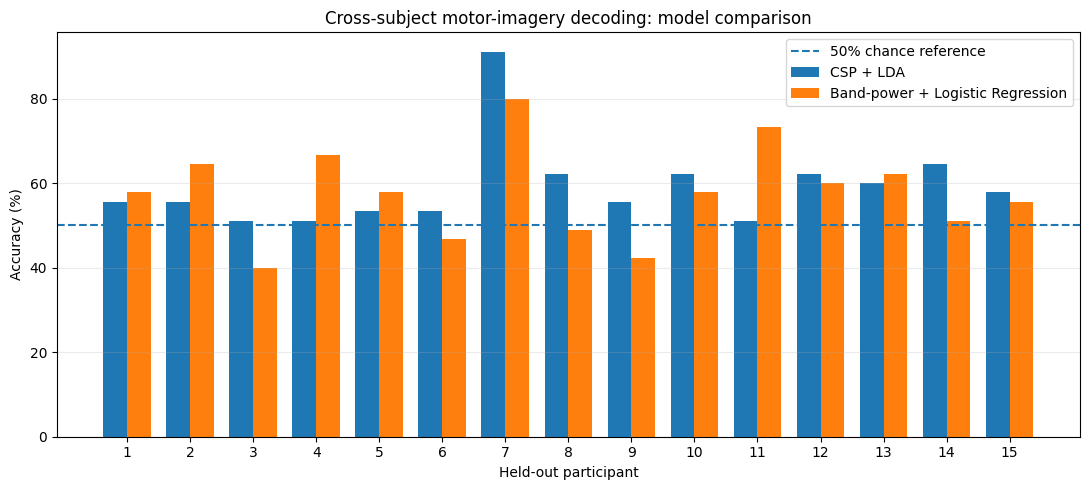

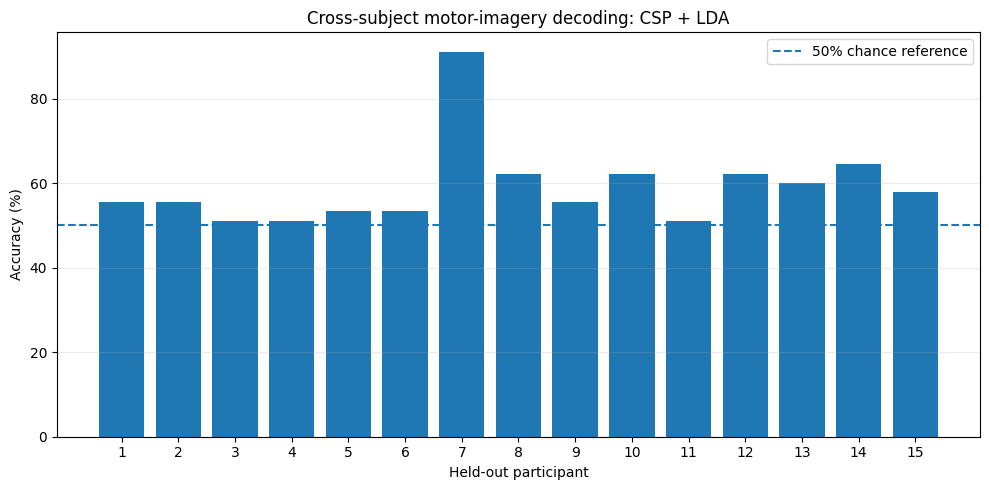

In [6]:
summary_rows = []
for model_name, acc_col, bal_col in [
    ("CSP + LDA", "csp_lda_accuracy", "csp_lda_balanced_accuracy"),
    ("Band-power + Logistic Regression", "baseline_accuracy", "baseline_balanced_accuracy")
]:
    summary_rows.append({
        "model": model_name,
        "participants_evaluated": len(results),
        "total_test_trials": int(results.n_test_trials.sum()),
        "mean_subject_accuracy": results[acc_col].mean(),
        "sd_subject_accuracy": results[acc_col].std(ddof=1),
        "median_subject_accuracy": results[acc_col].median(),
        "min_subject_accuracy": results[acc_col].min(),
        "max_subject_accuracy": results[acc_col].max(),
        "mean_subject_balanced_accuracy": results[bal_col].mean(),
        "chance_reference": 0.5
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUT / "cross_subject_summary.csv", index=False)
display(summary)

# Compare participant-level accuracy for the two models.
fig, ax = plt.subplots(figsize=(11, 5))
xpos = np.arange(len(results))
width = 0.38
ax.bar(xpos - width/2, results.csp_lda_accuracy * 100, width, label="CSP + LDA")
ax.bar(xpos + width/2, results.baseline_accuracy * 100, width, label="Band-power + Logistic Regression")
ax.axhline(50, linestyle="--", linewidth=1.5, label="50% chance reference")
ax.set_xticks(xpos)
ax.set_xticklabels(results.held_out_subject.astype(str))
ax.set_xlabel("Held-out participant")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Cross-subject motor-imagery decoding: model comparison")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "model_comparison_accuracy.png", dpi=180)
plt.show()

# Retain the original CSP + LDA accuracy chart for continuity.
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(results.held_out_subject.astype(str), results.csp_lda_accuracy * 100)
ax.axhline(50, linestyle="--", label="50% chance reference")
ax.set_xlabel("Held-out participant")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Cross-subject motor-imagery decoding: CSP + LDA")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "cross_subject_accuracy.png", dpi=180)
plt.show()

## 6. Confusion matrices

Pooled confusion matrices summarize the held-out predictions from the LOSO evaluation for each model. The matrices show the number of correct classifications and the distribution of left- and right-class errors.

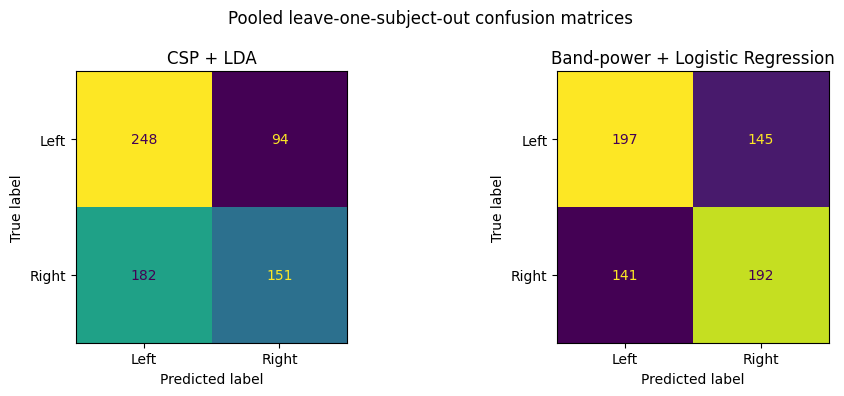

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, y_true, y_pred, title in [
    (axes[0], all_true_csp, all_pred_csp, "CSP + LDA"),
    (axes[1], all_true_base, all_pred_base, "Band-power + Logistic Regression")
]:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=["Left", "Right"])
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(title)
fig.suptitle("Pooled leave-one-subject-out confusion matrices")
fig.tight_layout()
fig.savefig(OUT / "pooled_confusion_matrices.png", dpi=180)
plt.show()

## 7. Participant-level performance

Participant-level results are examined to characterize variation in decoding performance. The highest-scoring participant is summarized separately, including class counts and a confusion matrix. This analysis provides context for interpreting unusually high or low participant-level scores.

In [8]:
best_row = results.loc[results.csp_lda_accuracy.idxmax()]
best_subject = int(best_row.held_out_subject)
best = subject_predictions[best_subject]
best_cm = confusion_matrix(best["y_true"], best["csp_lda"], labels=[0, 1])

print(f"Highest CSP-LDA accuracy: S{best_subject:03d}")
print(f"Accuracy: {best_row.csp_lda_accuracy:.3f}")
print(f"Balanced accuracy: {best_row.csp_lda_balanced_accuracy:.3f}")
print("True class counts:", pd.Series(best["y_true"]).value_counts().sort_index().to_dict())
print("Confusion matrix (rows=actual, columns=predicted; left=0, right=1):")
display(pd.DataFrame(best_cm, index=["Actual left", "Actual right"],
                     columns=["Predicted left", "Predicted right"]))

if best_subject == 7:
    print("Participant 7 is the highest-scoring participant; inspect its recordings and predictions carefully.")
else:
    print(f"Participant 7 accuracy: "
          f"{results.loc[results.held_out_subject == 7, 'csp_lda_accuracy'].squeeze() if 7 in results.held_out_subject.values else 'not evaluated'}")

if len(results) > 1:
    without_best = results.loc[results.held_out_subject != best_subject, "csp_lda_accuracy"].mean()
    print(f"Mean CSP-LDA accuracy excluding S{best_subject:03d}: {without_best:.3f}")

Highest CSP-LDA accuracy: S007
Accuracy: 0.911
Balanced accuracy: 0.911
True class counts: {0: 23, 1: 22}
Confusion matrix (rows=actual, columns=predicted; left=0, right=1):


              Predicted left  Predicted right
Actual left               21                2
Actual right               2               20

Participant 7 is the highest-scoring participant; inspect its recordings and predictions carefully.
Mean CSP-LDA accuracy excluding S007: 0.568


## 8. Results and limitations

### What I found

Across the 15 participants, CSP + LDA achieved an average accuracy of 59.1% and an average balanced accuracy of 58.5%. The band-power + Logistic Regression model achieved an average accuracy of 57.6% and balanced accuracy of 57.5%. The difference between the two approaches was small, so these results do not show a clear advantage for either model.

Performance varied across participants. The highest CSP + LDA accuracy was 91.1% for participant S007. Its confusion matrix showed 21 left-hand trials and 20 right-hand trials classified correctly, with two errors in each class. When S007 was excluded, the average CSP + LDA accuracy across the remaining 14 participants was 56.8%.

Overall, the models performed differently across individuals, and the high result for one participant had a noticeable effect on the average. The results suggest that classifying imagined movements across people is challenging, even when the same channels and preprocessing steps are used.

### Limitations

- The analysis used 15 participants from one publicly available dataset, with 45 trials per participant.
- Classification performance varied across participants, and the overall average does not represent every individual's result.
- The difference between the two models was small; this analysis does not establish that one approach is consistently better than the other.
- The analysis used offline EEG recordings and does not demonstrate performance in a real-time brain-computer interface.
- The models were evaluated on one dataset only, so the results may not carry over to other datasets or groups of people.
- The filtering, selected EEG channels, and model settings were chosen for this exploratory project and have not been tested across a wider range of settings.

### Outputs

The analysis generates participant-level trial counts, classification results for both models, summary performance metrics, accuracy comparison plots, and confusion matrices. These files are saved in the `outputs` directory.


## 9. References and dataset notes

- PhysioNet, EEG Motor Movement/Imagery Dataset (EEGMMIDB): https://physionet.org/content/eegmmidb/1.0.0/
- MNE-Python, EEGBCI dataset documentation: https://mne.tools/stable/generated/mne.datasets.eegbci.load_data.html
- MNE-Python, Common Spatial Patterns (CSP) documentation: https://mne.tools/stable/generated/mne.decoding.CSP.html
- scikit-learn, Linear Discriminant Analysis: https://scikit-learn.org/stable/modules/lda_qda.html
- scikit-learn, Logistic Regression: https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression

This work is an independent exploratory analysis of a publicly available EEG dataset. It evaluates offline classification performance.
